# Complex Analysis: the Bridge from Circuit Theory to Modern Physics

The same mathematics shows up four times:

| stop | the object | complex analysis does... | checked against |
|---|---|---|---|
| 1. circuits | RLC poles | **residues** give the time response | matrix exponential $e^{At}$ |
| 2. special functions | $J_n(x)$ | a **contour integral** defines it, and $I_n$ is $J_n$ on the imaginary axis | SciPy |
| 3. modern physics | quantum-corral energy levels | **zeros** of $J_n$, counted by the argument principle | matrix eigenvalues |
| 4. a machined part | aluminum disk vibration | $J$ and $I$ together give the mode eigenvalues | published plate tables |

The common thread is that **eigenvalues are where a function of a complex variable
blows up or vanishes**. Circuit poles, Bessel zeros, and quantum energy levels are
all the same idea.

Code: [`dgs/complex_eigen_bridge.py`](../dgs/complex_eigen_bridge.py). It reuses
[`complex_numerics.contour_integral`](../dgs/complex_numerics.py) and
[`bessel_linalg`](../dgs/bessel_linalg.py).

In [1]:
import sys, pathlib
sys.path.insert(0, str(pathlib.Path.cwd().parent))

import numpy as np
import matplotlib.pyplot as plt
from scipy import special

from dgs.complex_numerics import contour_integral
from dgs.complex_eigen_bridge import (
    rlc_state_matrix, rlc_poles, rlc_impulse_current_residues, rlc_impulse_current_expm,
    bessel_j_contour, bessel_i_from_j, bessel_zeros_scipy, bessel_zeros_matrix,
    count_zeros_argument_principle, corral_energies_eV, corral_density,
    clamped_plate_lambdas, clamped_plate_frequencies, machining_cost, AL6061,
)

# 1. Circuits: poles = eigenvalues = residues

Take a series RLC driven by $v(t)$, with state $x = [q,\,i]$:

$$\dot x = \underbrace{\begin{pmatrix}0 & 1\\ -\tfrac{1}{LC} & -\tfrac{R}{L}\end{pmatrix}}_{A} x + \begin{pmatrix}0\\ 1/L\end{pmatrix} v$$

- **Eigenvalues of $A$** satisfy $\det(sI - A) = s^2 + \tfrac{R}{L}s + \tfrac{1}{LC} = 0$.
- **Poles of the transfer function** $I(s)/V(s) = \dfrac{sC}{LCs^2 + RCs + 1}$ are the roots of the same polynomial.

So the two are the same numbers. The impulse response is the inverse Laplace
transform. Close the Bromwich contour to the left and it becomes a **sum of residues**:

$$i(t) = \sum_{\text{poles } p} \frac{1}{2\pi i}\oint_{|s-p|=r} I(s)\,e^{st}\,ds$$

Below, each residue is a literal numerical contour integral. It's compared against
$i(t) = [e^{At}b]_2$ from the matrix exponential, which uses no complex analysis at all.

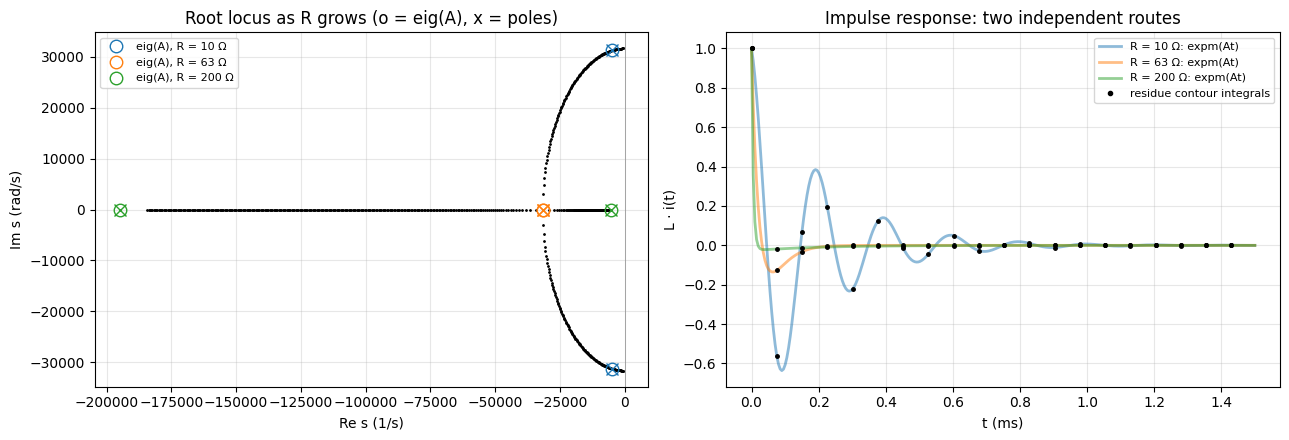

R =   10.00 Ω: max relative difference 4.4e-16
R =   63.25 Ω: max relative difference 2.3e-16
R =  200.00 Ω: max relative difference 2.3e-16


In [2]:
L_, C_ = 1e-3, 1e-6
Rc = 2*np.sqrt(L_/C_)
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
Rs = np.linspace(1, 3*Rc, 400)
P = np.array([np.sort_complex(rlc_poles(R, L_, C_)) for R in Rs])
axes[0].plot(P[:, 0].real, P[:, 0].imag, "k.", ms=2); axes[0].plot(P[:, 1].real, P[:, 1].imag, "k.", ms=2)
for R, col in ((10, "C0"), (Rc, "C1"), (200, "C2")):
    ev = np.linalg.eigvals(rlc_state_matrix(R, L_, C_))
    axes[0].plot(ev.real, ev.imag, "o", color=col, ms=9, mfc="none", label=f"eig(A), R = {R:.0f} Ω")
    axes[0].plot(rlc_poles(R, L_, C_).real, rlc_poles(R, L_, C_).imag, "x", color=col, ms=8)
axes[0].set(xlabel="Re s (1/s)", ylabel="Im s (rad/s)", title="Root locus as R grows (o = eig(A), x = poles)")
axes[0].axvline(0, color="0.6", lw=0.6); axes[0].legend(fontsize=8); axes[0].grid(alpha=0.3)

t = np.linspace(0, 1.5e-3, 300)
for R, col in ((10, "C0"), (Rc, "C1"), (200, "C2")):
    axes[1].plot(1e3*t, rlc_impulse_current_expm(R, L_, C_, t)*L_, col, lw=2, alpha=0.5,
                 label=f"R = {R:.0f} Ω: expm(At)")
    tt = t[::15]
    axes[1].plot(1e3*tt, rlc_impulse_current_residues(R, L_, C_, tt)*L_, "k.", ms=5)
axes[1].plot([], [], "k.", label="residue contour integrals")
axes[1].set(xlabel="t (ms)", ylabel="L · i(t)", title="Impulse response: two independent routes")
axes[1].legend(fontsize=8); axes[1].grid(alpha=0.3)
plt.tight_layout(); plt.show()

for R in (10, Rc, 200):
    a = rlc_impulse_current_residues(R, L_, C_, t[::15]); b = rlc_impulse_current_expm(R, L_, C_, t[::15])
    print(f"R = {R:7.2f} Ω: max relative difference {np.max(abs(a-b))/np.max(abs(b)):.1e}")

**A numerical lesson.** Why use a small circle around each pole instead of
one big circle around both? On the contour, $|e^{st}| = e^{\mathrm{Re}(s)\,t}$. A
large circle reaches far into the right half-plane, where $e^{st}$ is astronomically
large, and the trapezoid rule loses everything to cancellation. The analytic answer
is the same for any contour, but the floating-point answer is not:

In [3]:
R, t_test = 10.0, 1e-3
I = lambda s: s*C_/(L_*C_*s**2 + R*C_*s + 1)
p = rlc_poles(R, L_, C_); center = p.mean().real
exact = rlc_impulse_current_expm(R, L_, C_, [t_test])[0]
print(f"exact i(1 ms) = {exact:.6f}")
for radius in (5e4, 1e5, 2e5, 4e5):
    val = (contour_integral(lambda s: I(s)*np.exp(s*t_test), center, radius, 4000)/(2j*np.pi)).real
    print(f"one circle, radius {radius:8.0e}: max |e^(st)| on contour ≈ e^{(center+radius)*t_test:5.1f},  result {val: .4e}")
print(f"small circles (module):                                    result {rlc_impulse_current_residues(R, L_, C_, [t_test])[0]: .6f}")

exact i(1 ms) = 6.820256
one circle, radius    5e+04: max |e^(st)| on contour ≈ e^ 45.0,  result  1.0554e+06
one circle, radius    1e+05: max |e^(st)| on contour ≈ e^ 95.0,  result  4.4915e+27
one circle, radius    2e+05: max |e^(st)| on contour ≈ e^195.0,  result  2.4797e+71
one circle, radius    4e+05: max |e^(st)| on contour ≈ e^395.0,  result  4.5178e+158
small circles (module):                                    result  6.820256


# 2. Bessel functions are contour integrals

The generating function $e^{(x/2)(t - 1/t)} = \sum_n J_n(x)\,t^n$ is a Laurent series,
so Cauchy's coefficient formula **defines** $J_n$:

$$J_n(x) = \frac{1}{2\pi i}\oint_{|t|=1} e^{\frac{x}{2}(t - 1/t)}\,t^{-n-1}\,dt
= \frac{1}{2\pi}\int_0^{2\pi} e^{i(x\sin\theta - n\theta)}\,d\theta$$

**Computer-engineering fact:** for an analytic periodic integrand, the plain
trapezoid rule converges **exponentially**, with error $\sim \rho^{-N}$, not $N^{-2}$.
That's why FFT-based methods are so accurate. The proof comes from complex analysis:
the error is set by how far the integrand extends analytically off the circle.

**Second fact:** the modified Bessel function $I_n$, which appears in heat flow,
evanescent fields, and fiber cladding, is just $J_n$ evaluated on the imaginary axis:
$I_n(x) = i^{-n}J_n(ix)$.

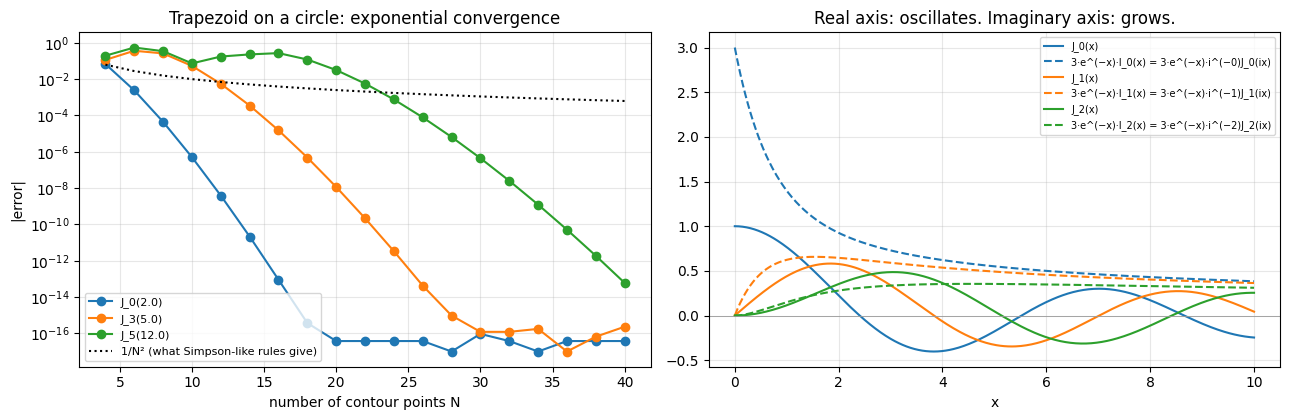

I_2(1.5):  via J on imaginary axis = 0.33783461833568074   scipy iv = 0.33783461833568074


In [4]:
Ns = np.arange(4, 41, 2)
fig, axes = plt.subplots(1, 2, figsize=(13, 4.3))
for (n, x), col in (((0, 2.0), "C0"), ((3, 5.0), "C1"), ((5, 12.0), "C2")):
    err = [abs(bessel_j_contour(n, x, N) - special.jv(n, x)) + 1e-17 for N in Ns]
    axes[0].semilogy(Ns, err, "o-", color=col, label=f"J_{n}({x})")
axes[0].semilogy(Ns, 1.0/Ns**2, "k:", label="1/N² (what Simpson-like rules give)")
axes[0].set(xlabel="number of contour points N", ylabel="|error|", title="Trapezoid on a circle: exponential convergence")
axes[0].legend(fontsize=8); axes[0].grid(alpha=0.3, which="both")

x = np.linspace(0, 10, 400)
for n, col in ((0, "C0"), (1, "C1"), (2, "C2")):
    axes[1].plot(x, special.jv(n, x), col, label=f"J_{n}(x)")
    axes[1].plot(x, bessel_i_from_j(n, x)/np.exp(x)*3, col, ls="--", label=f"3·e^(−x)·I_{n}(x) = 3·e^(−x)·i^(−{n})J_{n}(ix)")
axes[1].axhline(0, color="0.6", lw=0.6)
axes[1].set(xlabel="x", title="Real axis: oscillates. Imaginary axis: grows."); axes[1].legend(fontsize=7); axes[1].grid(alpha=0.3)
plt.tight_layout(); plt.show()
print("I_2(1.5):  via J on imaginary axis =", bessel_i_from_j(2, 1.5), "  scipy iv =", special.iv(2, 1.5))

# 3. Modern physics: Bessel zeros are energy levels

A particle confined to a disk of radius $a$ obeys
$-\frac{\hbar^2}{2m}\nabla^2\psi = E\psi$ with $\psi(a) = 0$. Separating in polar
coordinates gives $\psi = J_m(kr)\cos m\theta$, and the wall condition $J_m(ka) = 0$
quantizes $k$:

$$E_{mn} = \frac{\hbar^2 j_{mn}^2}{2 m^\* a^2}$$

This system exists. In 1993, Crommie, Lutz and Eigler at IBM arranged 48 iron atoms
in a ring of radius 7.13 nm on Cu(111) (the **quantum corral**), and imaged the
standing waves of the surface electrons ($m^\* \approx 0.38\,m_e$).

The zeros $j_{mn}$, found three independent ways:

In [5]:
print(f"{'n':>3s} {'scipy jn_zeros':>16s} {'eig(radial matrix)':>20s}")
for n, (a, b) in enumerate(zip(bessel_zeros_scipy(0, 5), bessel_zeros_matrix(0, 5)), 1):
    print(f"{n:3d} {a:16.8f} {b:20.8f}")
for c, r in ((8.0, 6.0), (5.0, 2.0), (12.0, 1.0)):
    print(f"argument principle: zeros of J_0 inside |z − {c}| < {r}: {count_zeros_argument_principle(0, c, r)}")

  n   scipy jn_zeros   eig(radial matrix)


  1       2.40482556           2.40482586
  2       5.52007811           5.52007722
  3       8.65372791           8.65371910
  4      11.79153444          11.79150560
  5      14.93091771          14.93085134
argument principle: zeros of J_0 inside |z − 8.0| < 6.0: 4
argument principle: zeros of J_0 inside |z − 5.0| < 2.0: 1
argument principle: zeros of J_0 inside |z − 12.0| < 1.0: 1


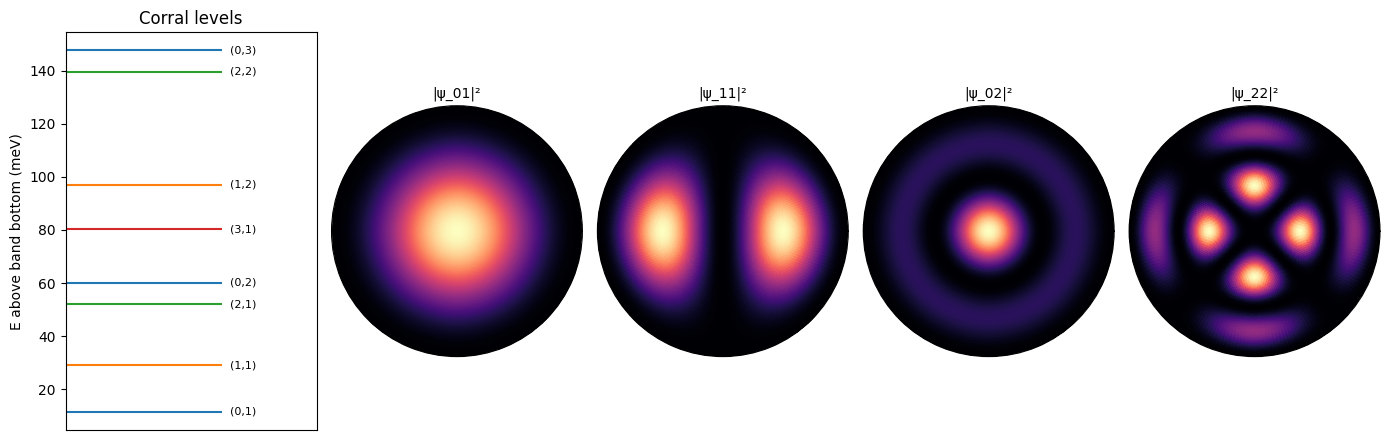

ground state E_01 = 11.4 meV,  E_02/E_01 = (j_02/j_01)² = 5.269


In [6]:
E = corral_energies_eV(7.13e-9)
fig = plt.figure(figsize=(14, 4.5))
ax = fig.add_subplot(1, 5, 1)
for e, m, n in E[:8]:
    ax.hlines(1e3*e, 0, 1, color=f"C{m}")
    ax.text(1.05, 1e3*e, f"({m},{n})", fontsize=8, va="center")
ax.set(xlim=(0, 1.6), xticks=[], ylabel="E above band bottom (meV)", title="Corral levels")
rr = np.linspace(0, 1, 200); th = np.linspace(0, 2*np.pi, 200)
Rg, Tg = np.meshgrid(rr, th)
for k, (m, n) in enumerate(((0, 1), (1, 1), (0, 2), (2, 2)), start=2):
    a2 = fig.add_subplot(1, 5, k, projection="polar")
    a2.pcolormesh(Tg, Rg, corral_density(m, n, Rg, Tg), cmap="magma", shading="auto")
    a2.set_xticks([]); a2.set_yticks([]); a2.set_title(f"|ψ_{m}{n}|²", fontsize=10)
plt.tight_layout(); plt.show()
print(f"ground state E_01 = {1e3*E[0][0]:.1f} meV,  E_02/E_01 = (j_02/j_01)² = {E[3][0]/E[0][0]:.3f}")

**The circuit connection.** The radial matrix in `bessel_linalg` is a discretized
operator. Its eigenvalues are $k^2$, exactly as the RLC state matrix's eigenvalues
are its poles. A circuit has 2 eigenvalues and a continuum has infinitely many, but
it's the same linear algebra. A ladder of $N$ LC cells gives $N$ eigenfrequencies,
and as $N\to\infty$ it becomes a transmission line, then a wave equation, then
Schrödinger's equation (see `engineering_eigenvalues.ipynb`).

# 4. A machined part: the clamped aluminum disk

Machine a thin 6061 disk and clamp its rim. Its bending vibrations obey the
biharmonic equation $D\nabla^4 w = \rho h\,\omega^2 w$. This factors as
$(\nabla^2 + k^2)(\nabla^2 - k^2)w = 0$, so the solution combines $J_m(kr)$
(oscillating) **and** $I_m(kr)$ ($J$ on the imaginary axis, from Part 2):

$$w = J_m(\lambda r/a) - \frac{J_m(\lambda)}{I_m(\lambda)}I_m(\lambda r/a),
\qquad \text{clamped: } J_m(\lambda)I_m'(\lambda) - I_m(\lambda)J_m'(\lambda) = 0$$

$$f = \frac{\lambda^2}{2\pi a^2}\sqrt{\frac{D}{\rho h}},\qquad D = \frac{E h^3}{12(1-\nu^2)}$$

The roots $\lambda^2$ below should reproduce the classic plate-vibration tables
(Leissa, *Vibration of Plates*, 1969): 10.216, 39.771, 89.104 for $m = 0$ and 21.26,
60.82 for $m = 1$.

λ² (m=0): [10.216 39.771 89.104]    λ² (m=1): [21.26  60.829]
6061 disk, radius 50 mm, thickness 2 mm, rim clamped: f = [ 2009.  7823. 17526.] Hz


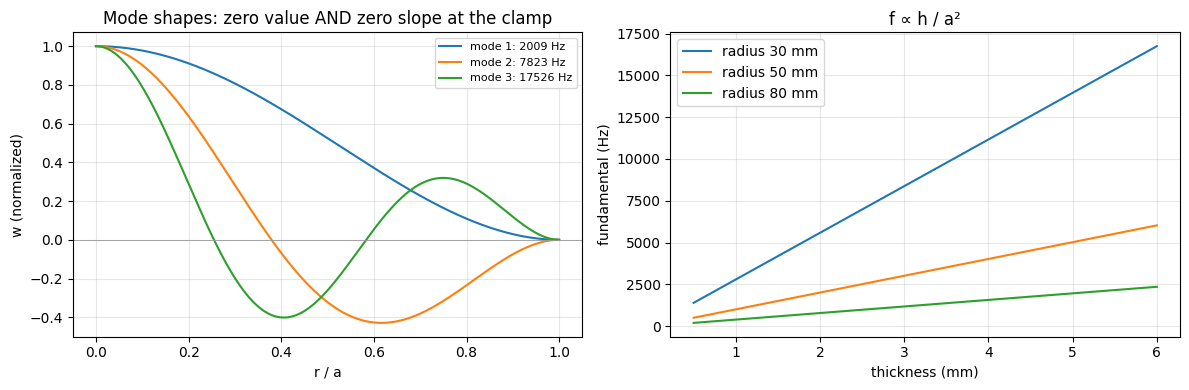

In [7]:
print("λ² (m=0):", np.round(clamped_plate_lambdas(0, 3)**2, 3), "   λ² (m=1):", np.round(clamped_plate_lambdas(1, 2)**2, 3))
a, h = 0.05, 0.002
f = clamped_plate_frequencies(a, h)
print(f"6061 disk, radius {1e3*a:.0f} mm, thickness {1e3*h:.0f} mm, rim clamped: f = {np.round(f, 0)} Hz")

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
r = np.linspace(0, 1, 300)
for k, lam in enumerate(clamped_plate_lambdas(0, 3)):
    w = special.jv(0, lam*r) - special.jv(0, lam)/special.iv(0, lam)*special.iv(0, lam*r)
    axes[0].plot(r, w/np.max(abs(w)), label=f"mode {k+1}: {f[k]:.0f} Hz")
axes[0].axhline(0, color="0.6", lw=0.6)
axes[0].set(xlabel="r / a", ylabel="w (normalized)", title="Mode shapes: zero value AND zero slope at the clamp")
axes[0].legend(fontsize=8); axes[0].grid(alpha=0.3)
hs = np.linspace(0.5e-3, 6e-3, 100)
for a_, col in ((0.03, "C0"), (0.05, "C1"), (0.08, "C2")):
    axes[1].plot(1e3*hs, [clamped_plate_frequencies(a_, hh)[0] for hh in hs], col, label=f"radius {1e3*a_:.0f} mm")
axes[1].set(xlabel="thickness (mm)", ylabel="fundamental (Hz)", title="f ∝ h / a²")
axes[1].legend(); axes[1].grid(alpha=0.3); plt.tight_layout(); plt.show()

**What would it cost to machine?** Below is a transparent cost model. **Every rate
is an assumption, so get real quotes.** A side note on machine choice: CNC mills like
Haas's go up to **5 axes**. "6-axis" usually refers to robot arms. A flat disk only
needs 2–3 axes (it's a lathe or simple mill job), so multi-axis machine time would
be overpaying.

In [8]:
stock = np.pi*0.055**2*0.006          # 110 mm dia x 6 mm plate stock
part = np.pi*0.05**2*0.002            # finished 100 mm dia x 2 mm disk
print(f"stock {1e6*stock:.1f} cm³, part {1e6*part:.1f} cm³, removed {1e6*(stock-part):.1f} cm³\n")
print(f"{'scenario':38s} {'material':>9s} {'hours':>6s} {'machine':>9s} {'total':>9s}")
for label, kw in (("3-axis job shop (assumed $90/hr)", dict(shop_rate_per_hr=90)),
                  ("default (assumed $120/hr)",        dict()),
                  ("5-axis time (assumed $200/hr)",    dict(shop_rate_per_hr=200)),
                  ("batch of 20: setup shared",        dict(setup_hr=1.0/20))):
    c = machining_cost(stock, stock - part, **kw)
    print(f"{label:38s} ${c['material']:8.2f} {c['machine_hours']:6.2f} ${c['machine']:8.2f} ${c['total']:8.2f}")

stock 57.0 cm³, part 15.7 cm³, removed 41.3 cm³

scenario                                material  hours   machine     total
3-axis job shop (assumed $90/hr)       $    1.23   1.05 $   94.65 $   95.88
default (assumed $120/hr)              $    1.23   1.05 $  126.20 $  127.43
5-axis time (assumed $200/hr)          $    1.23   1.05 $  210.33 $  211.56
batch of 20: setup shared              $    1.23   0.10 $   12.20 $   13.43


The aluminum itself costs about a dollar. **Setup time dominates** a one-off part,
which is why batching cuts the per-part cost several times over. The engineering
lesson: for small parts, the cost is mostly machine hours, not metal.

# Summary: one idea, four disguises

| | operator | eigenvalue condition | complex-analysis tool |
|---|---|---|---|
| RLC circuit | state matrix $A$ | $\det(sI - A) = 0$ | residues → $i(t)$ |
| Bessel function | Bessel's ODE | — | Cauchy coefficient integral, $I_n = i^{-n}J_n(ix)$ |
| quantum corral | $-\frac{\hbar^2}{2m}\nabla^2$ on a disk | $J_m(ka) = 0$ | argument principle counts the levels |
| aluminum disk | $D\nabla^4$ | $J_mI_m' - I_mJ_m' = 0$ | $J$ on both the real and imaginary axes |

**Roadmap from your courses to this notebook:** circuit theory (Laplace, poles) →
linear algebra (eigenvalues) → complex analysis (residues, contours) →
modern physics and quantum mechanics (Schrödinger in 2-D) → mechanics of materials
(plates).

## Exercises
1. Add a second LC loop coupled by mutual inductance $M$. Show that the 4×4 state
   matrix's eigenvalues split into two normal-mode pairs as $M$ grows.
2. Use `bessel_j_contour` to check the recurrence $J_{n-1} + J_{n+1} = \frac{2n}{x}J_n$.
3. Hydrogen in 2-D (a "flatland atom"): look up its energy formula and compare it
   with the corral's $1/a^2$ scaling. Why does one depend on $n^2$ and the other on $j_{mn}^2$?
4. Find the thickness of an $a$ = 50 mm aluminum disk whose fundamental is 440 Hz
   (concert A). Is it machinable?
5. Replace the clamped rim with a **free** rim. Look up the boundary condition and
   find the new $\lambda^2$ with `brentq`.